Preparação OpenDSS

In [1]:
import pandas as pd
import py_dss_interface
from py_dss_toolkit import dss_tools

dss_file = r"C:\Dados_teste\OpenDSS\GWO\Alim_Meia_Ponte_5_REDUZIDO\Master_PyDSS_Interface.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

dss.text(f"compile [{dss_file}]")
dss.text("buscoords buscoords.csv")

def decide_element(bus: str, buses_df: pd.DataFrame, trafo_df: pd.DataFrame, lines_df: pd.DataFrame):
    bus = bus.split(".")[0]
    elements_query = buses_df.query(f"name == '{bus}'")["all_pde_active_bus"].iloc[0]

    distance = 1e6
    for element in elements_query:
        element_type, element_name = element.split(".")

        if element_type == "Line":
            segment_df = lines_df.query(f"name == '{element_name}'")

            element_bus = segment_df["bus_name"].iloc[0]
            distance_bus = buses_df.query(f"name == '{element_bus}'")["distance"].iloc[0]

            if "mt" in element_name:
                kv = 13.8

            elif "bt" in element_name:
                kv = 0.38

            else:
                continue

        elif element_type == "Transformer":
            element_bus = trafo_df.query(f"name == '{element_name}'")["bus_name"].iloc[0]
            distance_bus = buses_df.query(f"name == '{element_bus}'")["distance"].iloc[0]
            kv = trafo_df.query(f"name == '{element_name}'")["kv"].iloc[0]

        else:
            continue

        if distance_bus < distance:
            distance = distance_bus
            selected_element = element_name
            selected_element_type = element_type
            selected_kv = kv

    return selected_element_type, selected_element, selected_kv

def calc_rpf() -> float:
    soma = 0
    for name in dss.monitors.names:
        if "voltage" in name:
            continue

        if "battery" in name:
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        soma += sum(x for x in monitor if x < 0)

    return soma

def calc_separated_rpf() -> tuple[float]:
    soma = 0
    soma_feeder = 0
    for name in dss.monitors.names:
        if "voltage" in name:
            continue

        if "battery" in name:
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        if "feeder" in name:  
            soma_feeder += sum(x for x in monitor if x < 0)
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        soma += sum(x for x in monitor if x < 0)

    return soma, soma_feeder

buses_df = dss_tools.model.buses_df
trafo_df = dss_tools.model.transformers_df
lines_df = dss_tools.model.lines_df

trafo_df["bus_name"] = trafo_df["bus"].str.split(".").str[0]
lines_df["bus_name"] = lines_df["bus1"].str.split(".").str[0]

buses_df = buses_df[["name", "distance", "all_pce_active_bus", "all_pde_active_bus"]]


Análise de Fluxo de Potência


Caso Base


,kwh,kvarh,zone kwh,zone losses kwh
0,45240.706519,66516.666107,120691.04002,6119.346322



Convergência das ações de controle:  1
Número de iterações de controle:  3

Caso Ótimo


,kwh,kvarh,zone kwh,zone losses kwh
0,42834.149609,65244.955579,120769.6253,5670.009513


,Caso,Fluxo Reverso Total (kWh),Fluxo Reverso Trafos (kWh),Fluxo Reverso Alimentador,Fitness
0,Caso Base,-25771.980858,-16004.490074,-9767.490784,41776.470932
1,Caso Ótimo,-20395.661722,-14997.051455,-5398.610268,35392.713177


Gráficos


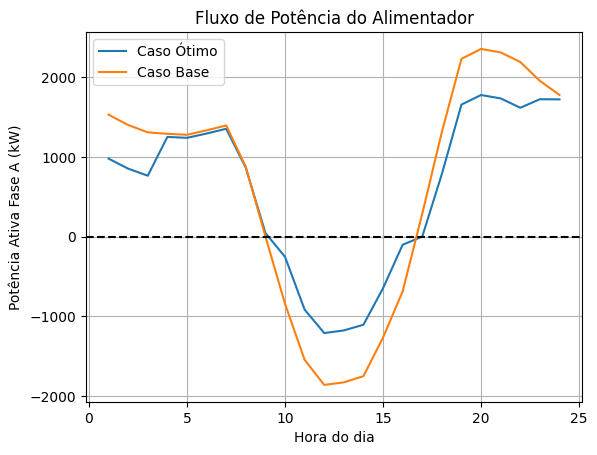

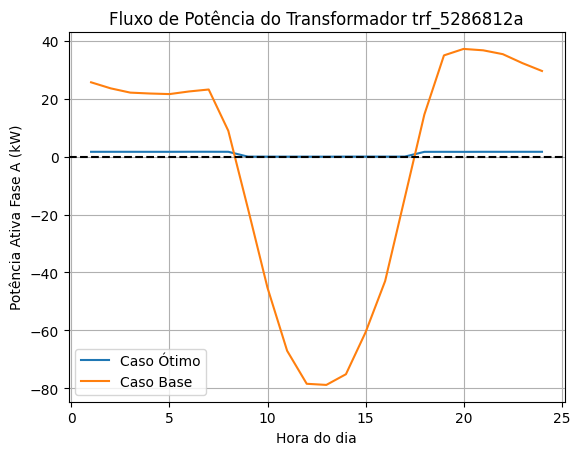

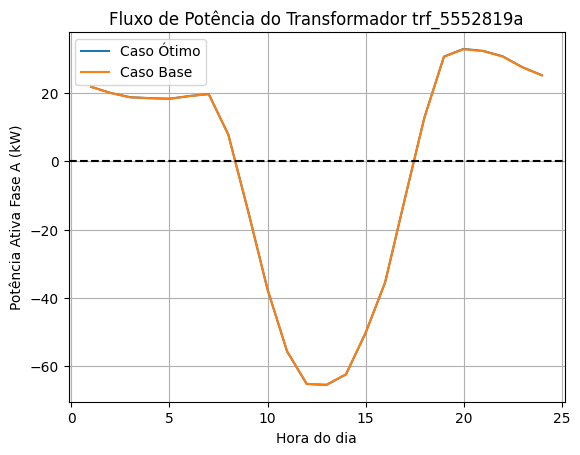

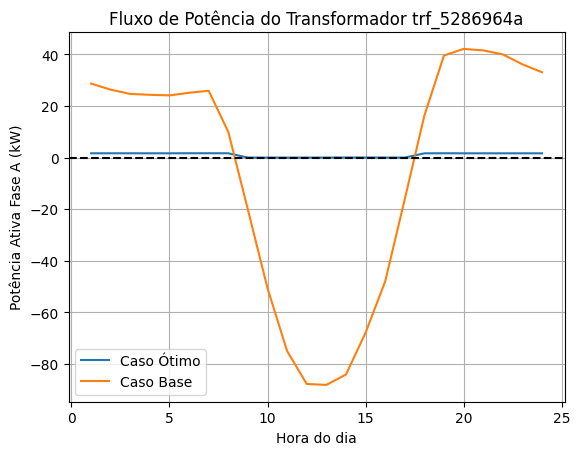

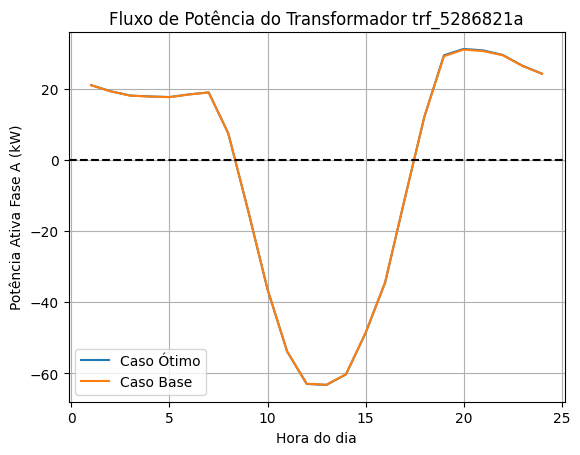

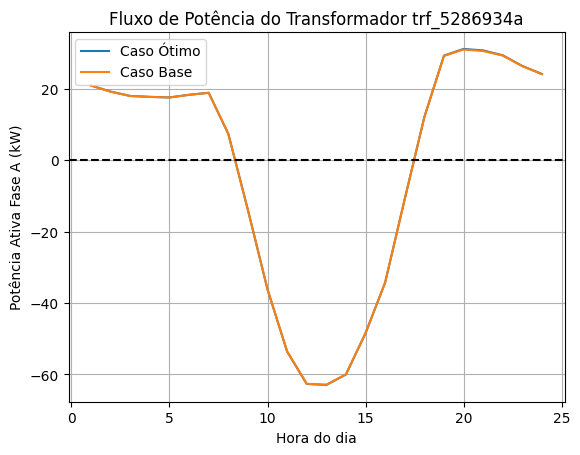

In [3]:
import py_dss_interface
from py_dss_toolkit import dss_tools
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

cases = ["Caso Base", "Caso Ótimo"]

#solution_buses = ['82064995002086', '82064995002086', '82034755002086', '82038115286835', '81489165002086'] #Solução encontrada (Não roda)
#solution_buses = ['82064995002086', '82064995002086', '94563015002086', '82022225286801', '82025985002086'] #Um dos indivíduos testados
#solution_buses = ['82034765002086', '82034745002086', '81488715002086', '82034735002086b', '82034755002086']
solution_buses = ['82034745002086', '82034765002086', '82036275286964', '81488725002086', '82026915286812'] #Solução encontrada para nova fitness function w1 = 2 (Melhor Fitness)
#solution_buses = ['82036275286964', '82034745002086', '82034765002086', '82034735002086', '81489075002086'] #Solução encontrada para nova fitness function w1 = 2 - Segunda tentativa (Melhor RPF)
#solution_buses = ['81489055002086', '82034765002086', '82026915286812', '81488705002086', '82036275286964'] #Solução encontrada para nova fitness w1 = 2 3a tentativa

#solution_powers =  [np.float64(45.23609993405461), np.float64(393.3943522539757), np.float64(498.59448293664593), np.float64(133.08149337090876), np.float64(495.1620137483599)]
#solution_powers = [62.73, 423.65, 497.77, 131.92, 498.61]
#solution_powers = [499.93, 499.91, 499.34, 499.99, 499.88]
solution_powers = [499.77, 497.89, 373.68, 499.56, 382.9] #Solução encontrada para nova fitness function w1 = 2 (Melhor RPF)
#solution_powers = [445.84, 498.81, 499.27, 497.85, 497.97] #Solução encontrada para nova fitness function w1 = 2 - Segunda tentativa (Melhor Fitness)
#solution_powers = [499.29, 499.96, 419.43, 499.98, 476.26] #Solução encontrada para nova fitness function w1 = 2 - Terceira tentativa 

powers = solution_powers

dss_file = r"C:\Dados_teste\OpenDSS\GWO\Alim_Meia_Ponte_5_REDUZIDO\Master_PyDSS_Interface.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

df_rpf = pd.DataFrame(columns=["Caso", "Fluxo Reverso Total (kWh)"])

voltage_dfs_base_case = {}

for case in cases:

    dss.text(f"compile [{dss_file}]")

    #dss.text("Redirect 'PV_System_120_MeiaPonte.dss'")
    dss.text("Redirect 'PVSystem_120_Irrad.dss")
    dss.text("buscoords buscoords.csv")

    if case == "Caso Ótimo":

        for i, (power, bus) in enumerate(zip(powers, solution_buses)):
            element_type, element_name, kv = decide_element(bus, buses_df, trafo_df, lines_df)
            pot = power

            dss.text(f"New Storage.Battery_{i} phases=3 bus1={bus} kv={kv} kWrated={pot} kWhrated={8*pot} dispmode=follow %stored=50")
            
            dss.text(f"New StorageController.SC_{i} element={element_type}.{element_name} terminal=1 modedis=peakShave elementList=[Battery_{i}]\n"
            f"~ MonPhase=AVG kwtarget=5 modecharge=peakShaveLow kwtargetLow=0\n\n")

            dss.text(f"New Monitor.Battery_{i} element=Storage.Battery_{i} mode=7")

    dss.text(f"buscoords BusCoords.csv")

    dss.text("set mode=daily")
    dss.text("set stepsize=1h")
    dss.text("set number=24")
    dss.text("set maxcontroliter=200")

    dss.solution.solve()

    energymeter_df = dss_tools.results.energymeters

    if case == "Caso Base":
        for name in dss.monitors.names:
            if not "voltage" in name:
                continue

            voltage_dfs_base_case[name] = dss_tools.results.monitor(name)

    elem_1, elem_2, elem_3, elem_4, elem_5 = "trf_5286812a", "trf_5552819a", "trf_5286964a", "trf_5286821a", "trf_5286934a"

    if case == "Caso Ótimo":
        print("\nConvergência das ações de controle: ", dss.solution.control_actions_done)
        print("Número de iterações de controle: ", dss.solution.control_iterations)

        df_optimal_feeder = dss_tools.results.monitor("feeder")
        df_optimal_trafo_1 = dss_tools.results.monitor(elem_1)
        df_optimal_trafo_2 = dss_tools.results.monitor(elem_2)
        df_optimal_trafo_3 = dss_tools.results.monitor(elem_3)
        df_optimal_trafo_4 = dss_tools.results.monitor(elem_4)
        df_optimal_trafo_5 = dss_tools.results.monitor(elem_5)

    elif case == "Caso Base":
        df_base_feeder = dss_tools.results.monitor("feeder")
        df_base_trafo_1 = dss_tools.results.monitor(elem_1)
        df_base_trafo_2 = dss_tools.results.monitor(elem_2)
        df_base_trafo_3  = dss_tools.results.monitor(elem_3)
        df_base_trafo_4  = dss_tools.results.monitor(elem_4)
        df_base_trafo_5  = dss_tools.results.monitor(elem_5)

    print(f"\n{case}")
    display(energymeter_df[["kwh", "kvarh", "zone kwh", "zone losses kwh"]])

    rpf = calc_rpf()
    rpf_transf, rpf_feeder = calc_separated_rpf()
    fitness = rpf_transf*2 + rpf_feeder  #w1 = 2
    
    df2 = pd.DataFrame(
        {
            "Caso": [case], 
            "Fluxo Reverso Total (kWh)": [rpf], 
            "Fluxo Reverso Trafos (kWh)": [rpf_transf], 
            "Fluxo Reverso Alimentador": [rpf_feeder],
            "Fitness": [abs(fitness)]
        }
    )

    df_rpf = pd.concat([df_rpf, df2], ignore_index=True)

#Fluxo reverso total
display(df_rpf)

#### Gráfico
print("Gráficos")

# Alimentador
plt.plot(df_optimal_feeder["Hour"], df_optimal_feeder[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_feeder["Hour"], df_base_feeder[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title("Fluxo de Potência do Alimentador")
plt.show()

#Trafo 5286812a
plt.plot(df_optimal_trafo_1["Hour"], df_optimal_trafo_1[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_1["Hour"], df_base_trafo_1[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title(f"Fluxo de Potência do Transformador {elem_1}")
plt.show()

#Trafo 5552819a

plt.plot(df_optimal_trafo_2["Hour"], df_optimal_trafo_2[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_2["Hour"], df_base_trafo_2[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title(f"Fluxo de Potência do Transformador {elem_2}")
plt.show()

#Trafo 5286964a

plt.plot(df_optimal_trafo_3["Hour"], df_optimal_trafo_3[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_3["Hour"], df_base_trafo_3[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_3}")
plt.show()

#Trafo 5286821a

plt.plot(df_optimal_trafo_4["Hour"], df_optimal_trafo_4[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_4["Hour"], df_base_trafo_4[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_4}")
plt.show()

#Trafo 5286934a

plt.plot(df_optimal_trafo_5["Hour"], df_optimal_trafo_5[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_5["Hour"], df_base_trafo_5[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_5}")
plt.show()

Análise das Barras

In [8]:
buses_df = dss_tools.model.buses_df
solution_buses_fixed = []

for bus in solution_buses:
    solution_buses_fixed.append(bus.split(".")[0])

display(buses_df.query(f"name in {solution_buses_fixed}"))

,name,nodes,num_nodes,kv_base,distance,coord_defined,x,y,latitude,longitude,all_pce_active_bus,all_pde_active_bus,line_list,line_total_miles,load_list,section_id,total_customers
445,82034745002086,"[1, 2, 3]",3,7.967434,0.158116,1,-49.322823,-16.578937,0.0,0.0,[Storage.battery_0],"[Line.smt_53072921, Line.smt_53074017]","[LINE.smt_53072921, LINE.smt_53074017]",0.0,[None],0,0
446,82034765002086,"[1, 2, 3]",3,7.967434,0.041984,1,-49.322710,-16.577917,0.0,0.0,[Storage.battery_1],"[Line.smt_53072922, Line.smt_53072967]","[LINE.smt_53072922, LINE.smt_53072967]",0.0,[None],0,0
1015,81488725002086,"[1, 2, 3]",3,7.967434,0.291219,1,-49.323600,-16.579815,0.0,0.0,[Storage.battery_3],"[Line.smt_53074019, Line.smt_53074020]","[LINE.smt_53074019, LINE.smt_53074020]",0.0,[None],0,0
1103,82026915286812,"[1, 2, 3, 4]",4,0.219393,8.798261,1,-49.334312,-16.624640,0.0,0.0,"[Load.m2_trf_5286812a, Load.m1_trf_5286812a, R...",[Transformer.trf_5286812a],[None],0.0,"[LOAD.m2_trf_5286812a, LOAD.m1_trf_5286812a]",0,0
1201,82036275286964,"[1, 2, 3, 4]",4,0.219393,5.884288,1,-49.320532,-16.615113,0.0,0.0,"[Load.m2_trf_5286964a, Load.m1_trf_5286964a, R...",[Transformer.trf_5286964a],[None],0.0,"[LOAD.m2_trf_5286964a, LOAD.m1_trf_5286964a]",0,0


In [17]:
colors = ["red", "blue", "green", "purple", "yellow"]
bus_list = []
for i, bus in enumerate(solution_buses):
    bus_list.append(dss_tools.interactive_view.circuit_get_bus_marker(name=bus, color=colors[i], size=10)) 

#bus_list = [dss_tools.interactive_view.circuit_get_bus_marker(name=solution_buses[3], color=colors[3], size=10)]

print(bus_list)

dss_tools.interactive_view.circuit_geoplot(parameter="active power", title="Circuit Plot with Solution Buses", show=True, bus_markers=bus_list)

[CircuitBusMarker(name='82034765002086', symbol='square', size=10, color='red', marker_name='82034765002086'), CircuitBusMarker(name='82034745002086', symbol='square', size=10, color='blue', marker_name='82034745002086'), CircuitBusMarker(name='81488715002086', symbol='square', size=10, color='green', marker_name='81488715002086'), CircuitBusMarker(name='82034735002086b', symbol='square', size=10, color='purple', marker_name='82034735002086b'), CircuitBusMarker(name='82034755002086', symbol='square', size=10, color='yellow', marker_name='82034755002086')]


In [13]:
adjacent_bus = "82041995002086"
buses_df.query(f"name == '{adjacent_bus}'")

,name,distance,all_pce_active_bus,all_pde_active_bus
993,82041995002086,6.517561,[None],"[Line.smt_53073789, Transformer.trf_5286833a]"
